Saving flight_demand.csv to flight_demand (2).csv

--- Рекомендации по направлениям ---
                   route  avg_load_factor  avg_elasticity                                                     strategy
0       Chicago - London         0.841158          6.7386              Снижать цены - высокая загрузка, чувствительные
1         Dubai - London         0.842113          6.6682              Снижать цены - высокая загрузка, чувствительные
2  Los Angeles - Bangkok         0.845342          6.6922              Снижать цены - высокая загрузка, чувствительные
3  New Delhi - Melbourne         0.839534          6.6532  Пересмотреть расписание - низкая загрузка, нечувствительные
4       New York - Paris         0.837796          6.6594  Пересмотреть расписание - низкая загрузка, нечувствительные
5  San Francisco - Seoul         0.838043          6.6796                      Промо - низкая загрузка, чувствительные
6  Singapore - Frankfurt         0.837639          6.6570  Пересмотреть расписа

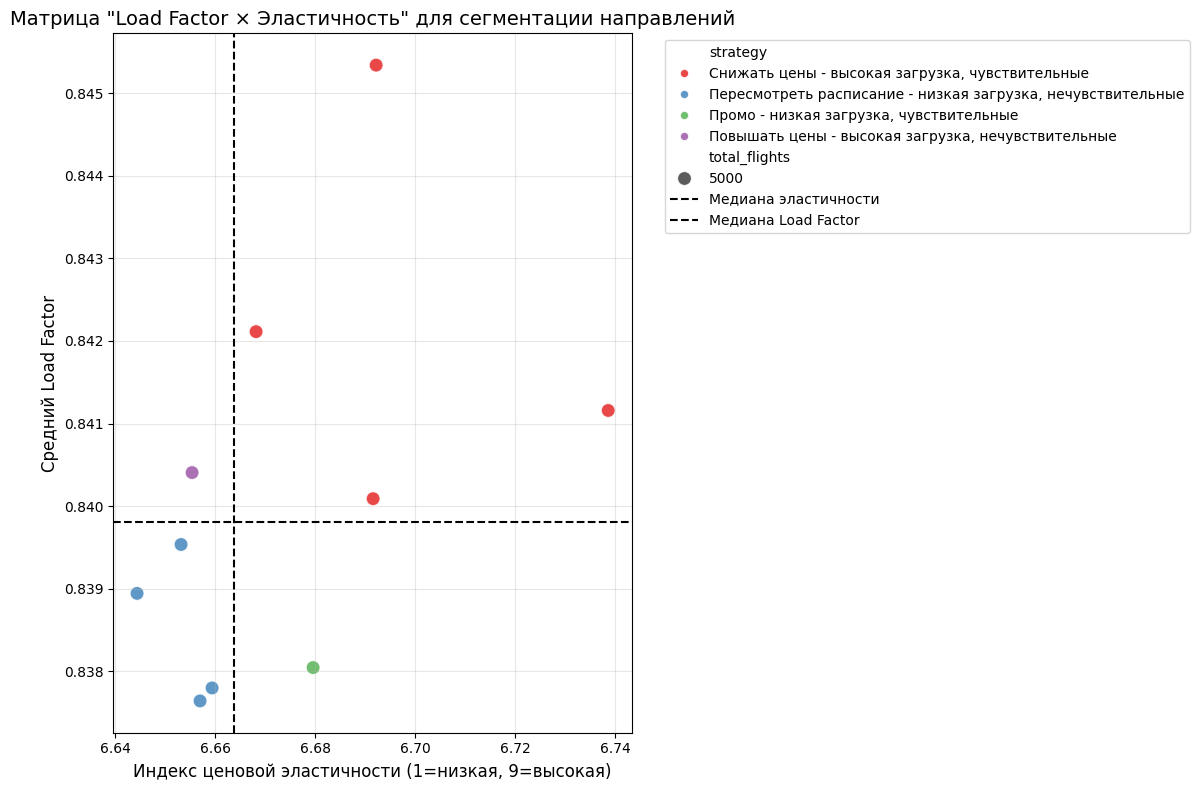

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import files

#Загрузка файла
uploaded = files.upload()
file_name = list(uploaded.keys())[0]
#Чтение данных
df = pd.read_csv(file_name)
#Метрики
df['load_factor'] = df['booked_seats'] / df['seat_capacity']
df['route'] = df['route_origin'] + ' - ' + df['route_destination']
#Агрегация по направлениям
route_stats = df.groupby('route').agg(
    avg_load_factor=('load_factor', 'mean'),
    avg_elasticity=('price_sensitivity_score', 'mean'),
    avg_price=('ticket_price', 'mean'),
    discount_share=('has_discount', 'mean'),
    total_flights=('flight_id', 'count')
).reset_index()

#Определение порогов
lf_median = route_stats['avg_load_factor'].median()
el_median = route_stats['avg_elasticity'].median()

#Стратегии
def get_strategy(row):
    if row['avg_load_factor'] >= lf_median and row['avg_elasticity'] >= el_median:
        return 'Снижать цены - высокая загрузка, чувствительные'
    elif row['avg_load_factor'] >= lf_median and row['avg_elasticity'] < el_median:
        return 'Повышать цены - высокая загрузка, нечувствительные'
    elif row['avg_load_factor'] < lf_median and row['avg_elasticity'] >= el_median:
        return 'Промо - низкая загрузка, чувствительные'
    else:
        return 'Пересмотреть расписание - низкая загрузка, нечувствительные'
route_stats['strategy'] = route_stats.apply(get_strategy, axis=1)
#Таблица
print("\n--- Рекомендации по направлениям ---")
print(route_stats[['route', 'avg_load_factor', 'avg_elasticity', 'strategy']].to_string())
#Матрица
plt.figure(figsize=(12, 8))
sns.scatterplot(
    data=route_stats,
    x='avg_elasticity',
    y='avg_load_factor',
    size='total_flights',
    hue='strategy',
    palette='Set1',
    sizes=(100, 400),
    alpha=0.8
)
plt.axvline(el_median, color='black', linestyle='--', label='Медиана эластичности')
plt.axhline(lf_median, color='black', linestyle='--', label='Медиана Load Factor')
plt.title('Матрица "Load Factor × Эластичность" для сегментации направлений', fontsize=14)
plt.xlabel('Индекс ценовой эластичности (1=низкая, 9=высокая)', fontsize=12)
plt.ylabel('Средний Load Factor', fontsize=12)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('matrix_load_factor.png', dpi=150)
plt.show()
#Сохранение в Excel
route_stats.to_excel('route_strategies.xlsx', index=False)
files.download('route_strategies.xlsx')